In [3]:

import os
import sys
import subprocess
import importlib.metadata as metadata

print("Python executable:", sys.executable)
print("Python version:", sys.version)

packages = [
    "chemprop",
    "torch",
    "rdkit",
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "seaborn"
]

for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: BELUM TERPASANG")

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("\nPyTorch:", torch.__version__)
print("CUDA tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Compute Capability:", torch.cuda.get_device_capability(0))

print("\nEnvironment check selesai.")


Python executable: /workspace/miniforge3/envs/chemprop/bin/python
Python version: 3.11.18 (main, Oct 26 2026, 11:35:17) [GCC 15.3.0]
chemprop: 2.3.1
torch: 2.5.1+cu124
rdkit: 2026.3.6
numpy: 2.4.6
pandas: 3.1.1
scikit-learn: 1.9.1
matplotlib: 3.11.2
seaborn: 0.13.2

PyTorch: 2.15.0+cu132
CUDA tersedia: True
GPU: Tesla V100-SXM2-32GB
Compute Capability: (7, 0)

Environment check selesai.


In [4]:

def run_chemprop_cli(args):
    command = [
        sys.executable,
        "-c",
        "from chemprop.cli.main import main; main()",
        *args
    ]

    return subprocess.run(
        command,
        capture_output=True,
        text=True
    )

# Memeriksa versi CLI
version_result = run_chemprop_cli(["--version"])

print("CHEMPROP VERSION")
print(version_result.stdout)
print(version_result.stderr)

# Memeriksa perintah train
train_help = run_chemprop_cli(["train", "--help"])

print("\nTRAIN CLI tersedia:", train_help.returncode == 0)

# Memeriksa perintah predict
predict_help = run_chemprop_cli(["predict", "--help"])

print("PREDICT CLI tersedia:", predict_help.returncode == 0)

if train_help.returncode != 0:
    print(train_help.stderr)

if predict_help.returncode != 0:
    print(predict_help.stderr)


CHEMPROP VERSION
chemprop 2.3.1



TRAIN CLI tersedia: True
PREDICT CLI tersedia: True


In [5]:

BASE_DIR = "/data/Zira/Chemprop_Kd_80"

DATA_PATH = os.path.join(
    BASE_DIR,
    "00_Dataset",
    "USP5_Kd_80_fixed.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "DMPNN_5Fold_Seed42"
)

FOLD_DIR = os.path.join(OUTPUT_DIR, "01_Folds")
MODEL_DIR = os.path.join(OUTPUT_DIR, "02_Models")
PRED_DIR = os.path.join(OUTPUT_DIR, "03_Predictions")
PLOT_DIR = os.path.join(OUTPUT_DIR, "04_Plots")
RESULT_DIR = os.path.join(OUTPUT_DIR, "05_Results")

for folder in [
    FOLD_DIR,
    MODEL_DIR,
    PRED_DIR,
    PLOT_DIR,
    RESULT_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Dataset:", DATA_PATH)
print("Output:", OUTPUT_DIR)
print("Folder berhasil disiapkan.")


Dataset: /data/Zira/Chemprop_Kd_80/00_Dataset/USP5_Kd_80_fixed.csv
Output: /data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42
Folder berhasil disiapkan.


In [6]:

from rdkit import Chem

df = pd.read_csv(DATA_PATH)

required_columns = [
    "Molecule ChEMBL ID",
    "Smiles",
    "pKd"
]

assert all(col in df.columns for col in required_columns), (
    "Kolom dataset tidak sesuai."
)

print("Ukuran dataset:", df.shape)
print("Kolom:", df.columns.tolist())

print("\nMissing values:")
print(df[required_columns].isna().sum())

df["pKd"] = pd.to_numeric(df["pKd"], errors="coerce")

valid_smiles = df["Smiles"].apply(
    lambda x: Chem.MolFromSmiles(str(x)) is not None
)

print("\nSMILES valid:", valid_smiles.sum())
print("SMILES tidak valid:", (~valid_smiles).sum())

print("\nStatistik pKd:")
display(df["pKd"].describe())

assert len(df) == 80, "Jumlah dataset bukan 80."
assert df[required_columns].notna().all().all(), (
    "Masih ada missing value."
)
assert valid_smiles.all(), "Ada SMILES tidak valid."
assert df["Smiles"].is_unique, (
    "Ada SMILES duplikat. Periksa sebelum melanjutkan."
)

print("\nDATASET VALID. Siap untuk 5-Fold CV.")
display(df.head())


Ukuran dataset: (80, 3)
Kolom: ['Molecule ChEMBL ID', 'Smiles', 'pKd']

Missing values:
Molecule ChEMBL ID    0
Smiles                0
pKd                   0
dtype: int64

SMILES valid: 80
SMILES tidak valid: 0

Statistik pKd:


count    80.000000
mean      4.121417
std       0.636259
min       3.031517
25%       3.643698
50%       4.099641
75%       4.531994
max       5.552842
Name: pKd, dtype: float64


DATASET VALID. Siap untuk 5-Fold CV.


,Molecule ChEMBL ID,Smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,CHEMBL4451435,O=C(O)CCc1nnc(-c2ccc(Cl)cc2)o1,3.346787
2,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
3,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272
4,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373


In [7]:

from sklearn.model_selection import KFold

SEED = 42

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

fold_summary = []

for fold, (train_idx, val_idx) in enumerate(
    kf.split(df), start=1
):

    train_df = df.iloc[train_idx].copy()
    val_df = df.iloc[val_idx].copy()

    fold_path = os.path.join(
        FOLD_DIR, f"Fold{fold:02d}"
    )

    os.makedirs(fold_path, exist_ok=True)

    train_df.to_csv(
        os.path.join(fold_path, "train.csv"),
        index=False
    )

    val_df.to_csv(
        os.path.join(fold_path, "validation.csv"),
        index=False
    )

    fold_summary.append({
        "Fold": fold,
        "Train_Size": len(train_df),
        "Validation_Size": len(val_df),
        "Train_File": os.path.join(fold_path, "train.csv"),
        "Validation_File": os.path.join(fold_path, "validation.csv")
    })

fold_summary_df = pd.DataFrame(fold_summary)

display(fold_summary_df)

fold_summary_df.to_csv(
    os.path.join(RESULT_DIR, "Fold_Summary.csv"),
    index=False
)

print("\nTotal fold:", len(fold_summary_df))
print("Total validation records:", sum(
    fold_summary_df["Validation_Size"]
))


,Fold,Train_Size,Validation_Size,Train_File,Validation_File
0,1,64,16,/data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42/0...,/data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42/0...
1,2,64,16,/data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42/0...,/data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42/0...
2,3,64,16,/data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42/0...,/data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42/0...
3,4,64,16,/data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42/0...,/data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42/0...
4,5,64,16,/data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42/0...,/data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42/0...



Total fold: 5
Total validation records: 80


In [8]:

CONFIG = {
    "hidden_dim": 300,
    "depth": 3,
    "dropout": 0.0,
    "batch_size": 16,
    "epochs": 100,
    "patience": 20,
    "aggregation": "norm",
    "aggregation_norm": 100,
    "featurizer": "V2",
    "tracking_metric": "rmse"
}

print("Konfigurasi model:")
display(pd.DataFrame(
    CONFIG.items(),
    columns=["Parameter", "Nilai"]
))


Konfigurasi model:


,Parameter,Nilai
0,hidden_dim,300
1,depth,3
2,dropout,0.0
3,batch_size,16
4,epochs,100
5,patience,20
6,aggregation,norm
7,aggregation_norm,100
8,featurizer,V2
9,tracking_metric,rmse


In [10]:
pred_path = os.path.join(
    PRED_DIR,
    "Fold01",
    "predictions.csv"
)

val_path = os.path.join(
    FOLD_DIR,
    "Fold01",
    "validation.csv"
)

pred_check = pd.read_csv(pred_path)
val_check = pd.read_csv(val_path)

print("ISI FILE PREDIKSI:")
display(pred_check.head())

print("\nISI FILE VALIDASI:")
display(val_check.head())

print("\nPerbandingan pKd:")
comparison = pred_check[["Smiles", "pKd"]].merge(
    val_check[["Smiles", "pKd"]],
    on="Smiles",
    suffixes=("_output", "_actual")
)

display(comparison.head(10))

ISI FILE PREDIKSI:


,Molecule ChEMBL ID,Smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,4.495879
1,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.313466
2,CHEMBL4463491,O=C(O)CCC(=O)c1cccs1,3.387729
3,CHEMBL4446091,Cc1cccc2c(=O)n(CC(=O)O)cnc12,3.877315
4,CHEMBL5270273,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CC=C(c3ccccc3)CC...,3.829645



ISI FILE VALIDASI:


,Molecule ChEMBL ID,Smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373
2,CHEMBL4463491,O=C(O)CCC(=O)c1cccs1,3.075721
3,CHEMBL4446091,Cc1cccc2c(=O)n(CC(=O)O)cnc12,3.309804
4,CHEMBL5270273,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CC=C(c3ccccc3)CC...,4.267606



Perbandingan pKd:


,Smiles,pKd_output,pKd_actual
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,4.495879,3.886057
1,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.313466,4.102373
2,O=C(O)CCC(=O)c1cccs1,3.387729,3.075721
3,Cc1cccc2c(=O)n(CC(=O)O)cnc12,3.877315,3.309804
4,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CC=C(c3ccccc3)CC...,3.829645,4.267606
5,CC(C)Cc1ccc(C(=O)CCC(=O)O)cc1,3.422042,3.408935
6,O=C(O)CNC(=O)c1csc(S(=O)(=O)N2CCC(c3ccccc3)CC2)c1,4.275035,4.173925
7,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2[C@@H]3CC[C@H]2C...,4.119778,4.060481
8,O=C(O)CCn1nnc(-c2ccccc2)n1,3.293310,3.275724
9,COc1ccc(Br)c(-c2nnc(CCC(=O)O)o2)c1,3.302033,3.568636


In [11]:

import os
import sys
import subprocess
import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

all_oof = []
fold_results = []

for fold in range(1, 6):

    print(f"\n{'='*50}")
    print(f"MEMPROSES FOLD {fold}")
    print(f"{'='*50}")

    fold_path = os.path.join(
        FOLD_DIR, f"Fold{fold:02d}"
    )

    train_path = os.path.join(fold_path, "train.csv")
    val_path = os.path.join(fold_path, "validation.csv")

    model_output = os.path.join(
        MODEL_DIR, f"Fold{fold:02d}"
    )

    prediction_output = os.path.join(
        PRED_DIR, f"Fold{fold:02d}"
    )

    os.makedirs(model_output, exist_ok=True)
    os.makedirs(prediction_output, exist_ok=True)

    checkpoint = os.path.join(
        model_output, "model_0", "best.pt"
    )

    # TRAINING HANYA JIKA CHECKPOINT BELUM ADA
    if not os.path.exists(checkpoint):

        print("Training Fold", fold, flush=True)

        train_command = [
            "train",
            "--data-path",
            train_path, val_path, val_path,
            "--smiles-columns", "Smiles",
            "--target-columns", "pKd",
            "--task-type", "regression",
            "--message-hidden-dim", "300",
            "--depth", "3",
            "--dropout", "0.0",
            "--batch-size", "16",
            "--epochs", "100",
            "--patience", "20",
            "--aggregation", "norm",
            "--aggregation-norm", "100",
            "--multi-hot-atom-featurizer-mode", "V2",
            "--metrics", "rmse", "mae", "r2",
            "--tracking-metric", "rmse",
            "--accelerator", "gpu",
            "--devices", "1",
            "--pytorch-seed", "42",
            "--output-dir", model_output
        ]

        train_result = run_chemprop_cli(train_command)

        train_log = (
            train_result.stdout + "\n" + train_result.stderr
        )

        with open(
            os.path.join(model_output, "training.log"), "w"
        ) as f:
            f.write(train_log)

        if (
            train_result.returncode != 0
            or not os.path.exists(checkpoint)
        ):
            raise RuntimeError(
                f"Training Fold {fold} gagal. Periksa training.log."
            )

    else:
        print("Checkpoint tersedia. Training dilewati.")

    # PREDICTION
    pred_path = os.path.join(
        prediction_output, "predictions.csv"
    )

    predict_command = [
        "predict",
        "--test-path", val_path,
        "--model-paths", checkpoint,
        "--preds-path", pred_path,
        "--smiles-columns", "Smiles",
        "--accelerator", "gpu",
        "--devices", "1"
    ]

    print("Predicting Fold", fold, flush=True)

    pred_result = run_chemprop_cli(predict_command)

    pred_log = (
        pred_result.stdout + "\n" + pred_result.stderr
    )

    with open(
        os.path.join(prediction_output, "prediction.log"), "w"
    ) as f:
        f.write(pred_log)

    if (
        pred_result.returncode != 0
        or not os.path.exists(pred_path)
    ):
        raise RuntimeError(
            f"Prediction Fold {fold} gagal."
        )

    # MEMBACA HASIL PREDIKSI
    pred_df = pd.read_csv(pred_path)
    actual_df = pd.read_csv(val_path)

    if "pKd" not in pred_df.columns:
        raise ValueError(
            f"Kolom pKd tidak ditemukan: {pred_df.columns.tolist()}"
        )

    pred_df = pred_df[
        ["Smiles", "pKd"]
    ].rename(columns={
        "pKd": "pKd_Predicted"
    })

    actual_df = actual_df[
        ["Molecule ChEMBL ID", "Smiles", "pKd"]
    ].rename(columns={
        "pKd": "pKd_Actual"
    })

    fold_oof = actual_df.merge(
        pred_df,
        on="Smiles",
        how="inner",
        validate="one_to_one"
    )

    if len(fold_oof) != len(actual_df):
        raise ValueError(
            f"Jumlah prediksi tidak cocok pada Fold {fold}"
        )

    fold_oof["Fold"] = fold

    fold_oof["Residual"] = (
        fold_oof["pKd_Actual"]
        - fold_oof["pKd_Predicted"]
    )

    fold_oof["Absolute_Error"] = abs(
        fold_oof["Residual"]
    )

    all_oof.append(fold_oof)

    y_true = fold_oof["pKd_Actual"]
    y_pred = fold_oof["pKd_Predicted"]

    fold_results.append({
        "Fold": fold,
        "N": len(fold_oof),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "Status": "Success"
    })

    print("Fold selesai:", fold)
    print("Jumlah prediksi:", len(fold_oof))

    # Simpan progres
    pd.concat(
        all_oof, ignore_index=True
    ).to_csv(
        os.path.join(RESULT_DIR, "OOF_Progress.csv"),
        index=False
    )

    pd.DataFrame(fold_results).to_csv(
        os.path.join(RESULT_DIR, "Fold_Metrics_Progress.csv"),
        index=False
    )

print("\nSELURUH 5 FOLD SELESAI")
display(pd.DataFrame(fold_results))



MEMPROSES FOLD 1
Checkpoint tersedia. Training dilewati.
Predicting Fold 1
Fold selesai: 1
Jumlah prediksi: 16

MEMPROSES FOLD 2
Training Fold 2
Predicting Fold 2
Fold selesai: 2
Jumlah prediksi: 16

MEMPROSES FOLD 3
Training Fold 3
Predicting Fold 3
Fold selesai: 3
Jumlah prediksi: 16

MEMPROSES FOLD 4
Training Fold 4
Predicting Fold 4
Fold selesai: 4
Jumlah prediksi: 16

MEMPROSES FOLD 5
Training Fold 5
Predicting Fold 5
Fold selesai: 5
Jumlah prediksi: 16

SELURUH 5 FOLD SELESAI


,Fold,N,RMSE,MAE,R2,Status
0,1,16,0.319331,0.254487,0.589754,Success
1,2,16,0.330845,0.279787,0.624460,Success
2,3,16,0.628524,0.529067,0.291943,Success
3,4,16,0.420773,0.318825,0.623845,Success
4,5,16,0.234995,0.187004,0.786813,Success


In [12]:

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

oof_df = pd.concat(
    all_oof,
    ignore_index=True
)

# Memastikan setiap senyawa muncul tepat satu kali
print("Jumlah prediksi:", len(oof_df))
print("Jumlah senyawa unik:", oof_df["Smiles"].nunique())

assert len(oof_df) == 80
assert oof_df["Smiles"].nunique() == 80
assert oof_df["Molecule ChEMBL ID"].nunique() == 80

# Urutan kolom
oof_df = oof_df[[
    "Molecule ChEMBL ID",
    "Smiles",
    "Fold",
    "pKd_Actual",
    "pKd_Predicted"
]]

oof_df["Residual"] = (
    oof_df["pKd_Actual"] - oof_df["pKd_Predicted"]
)

oof_df["Absolute_Error"] = abs(oof_df["Residual"])

# Metrik gabungan 80 prediksi OOF
y_true = oof_df["pKd_Actual"]
y_pred = oof_df["pKd_Predicted"]

oof_metrics = {
    "N": len(oof_df),
    "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    "MAE": mean_absolute_error(y_true, y_pred),
    "R2": r2_score(y_true, y_pred)
}

metrics_df = pd.DataFrame([oof_metrics])

print("HASIL EVALUASI OOF")
display(metrics_df)

# Simpan hasil
oof_df.to_csv(
    os.path.join(RESULT_DIR, "OOF_Predictions_80.csv"),
    index=False
)

metrics_df.to_csv(
    os.path.join(RESULT_DIR, "OOF_Metrics.csv"),
    index=False
)

print("Prediksi OOF dan metrik berhasil disimpan.")


Jumlah prediksi: 80
Jumlah senyawa unik: 80
HASIL EVALUASI OOF


,N,RMSE,MAE,R2
0,80,0.409572,0.313834,0.580381


Prediksi OOF dan metrik berhasil disimpan.


In [13]:

fold_metrics_df = pd.DataFrame(fold_results)

print("METRIK SETIAP FOLD")
display(fold_metrics_df)

print("\nRATA-RATA DAN STANDAR DEVIASI")

summary_metrics = fold_metrics_df[
    ["RMSE", "MAE", "R2"]
].agg(["mean", "std"])

display(summary_metrics)

fold_metrics_df.to_csv(
    os.path.join(RESULT_DIR, "Fold_Metrics.csv"),
    index=False
)

summary_metrics.to_csv(
    os.path.join(RESULT_DIR, "Fold_Metrics_Summary.csv")
)


METRIK SETIAP FOLD


,Fold,N,RMSE,MAE,R2,Status
0,1,16,0.319331,0.254487,0.589754,Success
1,2,16,0.330845,0.279787,0.624460,Success
2,3,16,0.628524,0.529067,0.291943,Success
3,4,16,0.420773,0.318825,0.623845,Success
4,5,16,0.234995,0.187004,0.786813,Success



RATA-RATA DAN STANDAR DEVIASI


,RMSE,MAE,R2
mean,0.386893,0.313834,0.583363
std,0.150260,0.129535,0.180060


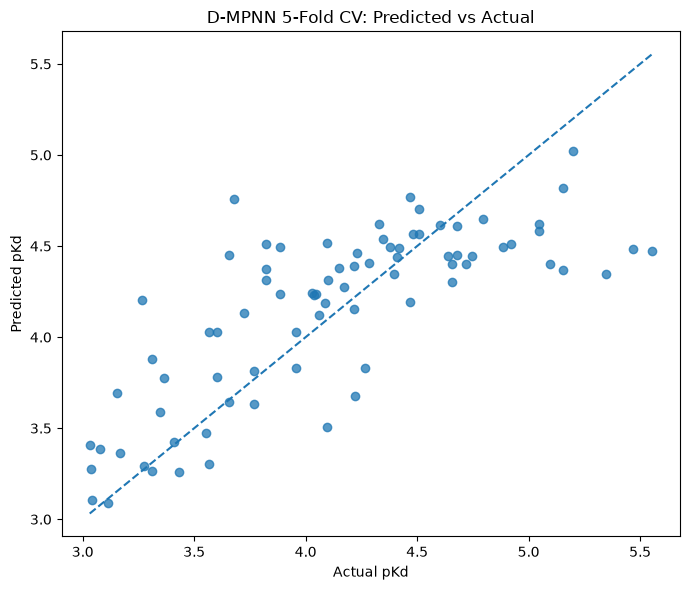

In [14]:

plt.figure(figsize=(7, 6))

plt.scatter(
    oof_df["pKd_Actual"],
    oof_df["pKd_Predicted"],
    alpha=0.75
)

minimum = min(
    oof_df["pKd_Actual"].min(),
    oof_df["pKd_Predicted"].min()
)

maximum = max(
    oof_df["pKd_Actual"].max(),
    oof_df["pKd_Predicted"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual pKd")
plt.ylabel("Predicted pKd")
plt.title("D-MPNN 5-Fold CV: Predicted vs Actual")

plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "01_Predicted_vs_Actual.png"),
    dpi=300
)
plt.show()


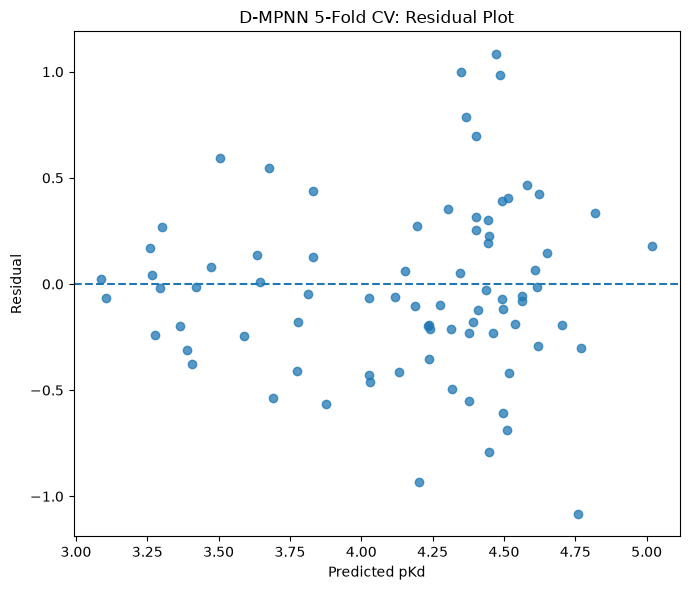

In [15]:

plt.figure(figsize=(7, 6))

plt.scatter(
    oof_df["pKd_Predicted"],
    oof_df["Residual"],
    alpha=0.75
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted pKd")
plt.ylabel("Residual")
plt.title("D-MPNN 5-Fold CV: Residual Plot")

plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "02_Residual_Plot.png"),
    dpi=300
)
plt.show()


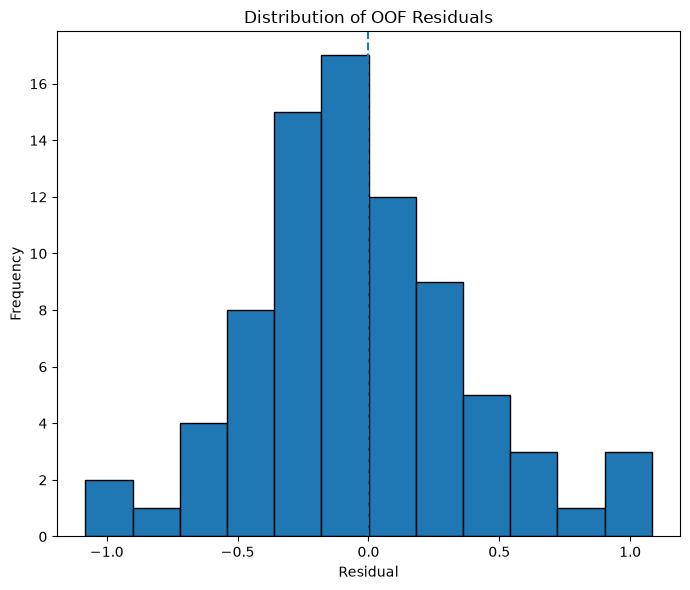

In [16]:

plt.figure(figsize=(7, 6))

plt.hist(
    oof_df["Residual"],
    bins=12,
    edgecolor="black"
)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of OOF Residuals")

plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "03_Residual_Distribution.png"),
    dpi=300
)
plt.show()


In [17]:

error_df = oof_df.sort_values(
    "Absolute_Error",
    ascending=False
)

print("10 SENYAWA DENGAN ERROR TERBESAR")

display(
    error_df[[
        "Molecule ChEMBL ID",
        "Fold",
        "pKd_Actual",
        "pKd_Predicted",
        "Residual",
        "Absolute_Error"
    ]].head(10)
)

error_df.to_csv(
    os.path.join(RESULT_DIR, "OOF_Error_Analysis.csv"),
    index=False
)


10 SENYAWA DENGAN ERROR TERBESAR


,Molecule ChEMBL ID,Fold,pKd_Actual,pKd_Predicted,Residual,Absolute_Error
33,CHEMBL5278336,3,5.552842,4.470640,1.082202,1.082202
50,CHEMBL5286558,4,3.677781,4.758929,-1.081148,1.081148
35,CHEMBL5410606,3,5.346787,4.348973,0.997814,0.997814
38,CHEMBL5266862,3,5.468521,4.485522,0.982999,0.982999
42,CHEMBL4581803,3,3.267606,4.202448,-0.934842,0.934842
61,CHEMBL5274321,4,3.657577,4.448422,-0.790845,0.790845
46,CHEMBL5270943,3,5.154902,4.367903,0.786999,0.786999
37,CHEMBL5273203,3,5.096910,4.401578,0.695332,0.695332
16,CHEMBL5276984,2,3.823909,4.511756,-0.687847,0.687847
0,CHEMBL5285743,1,3.886057,4.495878,-0.609821,0.609821


In [18]:

print("LOKASI OUTPUT:", OUTPUT_DIR)

for root, dirs, files in os.walk(OUTPUT_DIR):
    level = root.replace(OUTPUT_DIR, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

print("\nNotebook workflow selesai.")


LOKASI OUTPUT: /data/Zira/Chemprop_Kd_80/DMPNN_5Fold_Seed42
DMPNN_5Fold_Seed42/
    03_Predictions/
        Fold04/
            predictions.csv
            prediction.log
        Fold01/
            predictions.csv
            prediction.log
        Fold05/
            predictions.csv
            prediction.log
        Fold03/
            predictions.csv
            prediction.log
        Fold02/
            predictions.csv
            prediction.log
    01_Folds/
        Fold04/
            train.csv
            validation.csv
        Fold01/
            train.csv
            validation.csv
        Fold05/
            train.csv
            validation.csv
        Fold03/
            train.csv
            validation.csv
        Fold02/
            train.csv
            validation.csv
    04_Plots/
        03_Residual_Distribution.png
        01_Predicted_vs_Actual.png
        02_Residual_Plot.png
    02_Models/
        Fold04/
            config.toml
            training.log
           